# Project 2: Players, Clubs and Islands in 30 Years of European Football Transfers

**Joao De Oliveira**

## Question
European football has two distinct kinds of nodes: **players** and **clubs**. A player is tied to every club he has played for, so all ties run *between* the two groups, never *within* them. What can we infer about each group, the clubs and the players, from this two-mode network?

## Data
[ewenme/transfers](https://github.com/ewenme/transfers) on GitHub: every transfer recorded on [Transfermarkt](https://www.transfermarkt.com/) for the clubs of 9 European leagues (Premier League, Championship, La Liga, Serie A, Bundesliga, Ligue 1, Liga Portugal, Eredivisie and the Russian Premier League) from the 1992/93 to 2022/23 seasons, which is about 177,000 transfer records. Each record names the player, his age and position, the club, the other club involved, the fee and whether it was a loan.

## Approach
1. Build the two-mode network: players x clubs, with an edge when a player joined or left a club.
2. Project it onto the clubs: two clubs are tied by the number of players they have shared.
3. Reduce the network with the island method (Tsvetovat & Kouznetsov, *Social Network Analysis for Startups*, Chapter 4): raise a "water level" on the edge weights and keep only ties above it, so that the tightly linked groups of clubs appear as islands.
4. Apply the same method to the players' side to find groups of players whose careers followed the same path.
5. Interpret both groups and check that the results are not driven by data problems.

## 0. Setup

In [22]:
import os, re
import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
from scipy import sparse, stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.set_option("display.max_colwidth", 120)
print("networkx", nx.__version__)

networkx 3.7


## 1. Load the data from GitHub
The repository has one CSV per league. I download each file once and cache it locally, so rerunning the notebook doesn't download them again.

In [23]:
BASE = "https://raw.githubusercontent.com/ewenme/transfers/master/data/"
LEAGUES = ["premier-league", "championship", "primera-division", "serie-a", "1-bundesliga",
           "ligue-1", "liga-nos", "eredivisie", "premier-liga"]
CACHE = "transfers_cache"
os.makedirs(CACHE, exist_ok=True)

frames = []
for lg in LEAGUES:
    path = os.path.join(CACHE, f"{lg}.csv")
    if not os.path.exists(path):
        pd.read_csv(BASE + f"{lg}.csv").to_csv(path, index=False)
    frames.append(pd.read_csv(path))
raw = pd.concat(frames, ignore_index=True)

print(f"Transfer records: {len(raw):,} | seasons {raw.year.min()}-{raw.year.max()}")
raw.groupby(["country", "league_name"]).size().rename("records").to_frame()

Transfer records: 177,412 | seasons 1992-2022


records
country     league_name              
England     Championship        24241
            Premier League      23675
France      Ligue 1             17580
Germany     1 Bundesliga        14158
Italy       Serie A             28433
Netherlands Eredivisie          15264
Portugal    Liga Nos            21734
Russia      Premier Liga        14947
Spain       Primera Division    17380

## 2. Clean the data
Three problems need fixing before building the network.

**1. Players have no ID, only a name.** Common names like "João Pedro" or "Fernando" belong to many different people. I identify a player by name + estimated birth year (transfer year minus age). Records of the same name are treated as one person when their birth years are within one year of each other.

**2. Some clubs appear under two names** after a rename or refounding (for example "FC Internazionale" → "Inter Milan", "Terek Grozny" → "Akhmat Grozny"). If I left them separate, a club would look strongly tied to itself. I merged only renames of the same club, checked by hand: same league, years that don't overlap, and many shared players.

**3. Positions** are recorded at different levels of detail, so I group them into Goalkeeper, Defender, Midfielder and Forward, as in Project 1.

In [24]:
d = raw.dropna(subset=["player_name", "club_name", "age"]).copy()

# 1 player identity: name + estimated birth year
d["birth_est"] = (d["year"] - d["age"]).astype(int)

def split_by_birth(group):
    years = np.sort(group["birth_est"].unique())
    person, ids, prev = 0, {}, None
    for y in years:
        if prev is not None and y - prev > 1:
            person += 1
        ids[y], prev = person, y
    return group["birth_est"].map(ids)

d["person"] = d.groupby("player_name", group_keys=False)[["birth_est"]].apply(split_by_birth)
d["player"] = d["player_name"] + " #" + d["person"].astype(str)


n_people = d.groupby("player_name")["person"].nunique()
AMBIGUOUS = set(n_people[n_people > 1].index) | {n for n in d["player_name"].unique() if len(n.split()) == 1}
d["ambiguous"] = d["player_name"].isin(AMBIGUOUS)

# 2 club renames
RENAMES = {
    "FC Internazionale": "Inter Milan", "Milan AC": "AC Milan",
    "AC Parma": "Parma", "Parma FC": "Parma", "Parma Calcio 1913": "Parma",
    "AC Fiorentina": "ACF Fiorentina", "Torino Calcio": "Torino FC", "SPAL 2013": "SPAL",
    "FC Empoli": "Empoli FC", "US Salernitana": "US Salernitana 1919",
    "Dinamo Moscow": "Dynamo Moscow", "Rostselmash Rostov": "FK Rostov", "PFK Tambov": "FK Tambov",
    "Торпедо-Лужники Москва": "Torpedo Moscow", "Torpedo-ZiL Moscow": "FC Moscow",
    "Torpedo-Metallurg Moscow": "FC Moscow", "Terek Grozny": "Akhmat Grozny",
    "Saturn REN-TV Ramenskoe": "Saturn Ramenskoe", "Spartak Vladikavkaz": "Alania Vladikavkaz",
    "Spartak-Alania Vladikavkaz": "Alania Vladikavkaz", "FC Pari Nizhniy Novgorod": "FC Nizhniy Novgorod",
    "Uralmash Ekaterinburg": "Ural Yekaterinburg", "Dinamo-Gazovik Tyumen": "FK Tyumen",
    "Belenenses SAD": "CF Os Belenenses", "Association Troyes Aube Champagne": "ESTAC Troyes",
    "FC Zwolle": "PEC Zwolle", "Cambuur-Leeuwarden bvo": "SC Cambuur-Leeuwarden",
    "SC Cambuur Leeuwarden": "SC Cambuur-Leeuwarden",
}
d["club"] = d["club_name"].replace(RENAMES)

# 3 position groups
POS = {"Goalkeeper": "Goalkeeper",
       "Centre-Back": "Defender", "Left-Back": "Defender", "Right-Back": "Defender", "Sweeper": "Defender",
       "defence": "Defender", "Defence": "Defender",
       "Central Midfield": "Midfielder", "Defensive Midfield": "Midfielder", "Attacking Midfield": "Midfielder",
       "Right Midfield": "Midfielder", "Left Midfield": "Midfielder", "midfield": "Midfielder",
       "Centre-Forward": "Forward", "Right Winger": "Forward", "Left Winger": "Forward",
       "Second Striker": "Forward", "attack": "Forward"}
d["pos_group"] = d["position"].map(POS)
d["loan"] = d["fee"].str.contains("loan", case=False, na=False)

print(f"Distinct names: {d.player_name.nunique():,} -> distinct players after the birth-year split: {d.player.nunique():,}")
print(f"Players with an ambiguous name: {d.drop_duplicates('player').ambiguous.mean():.1%}")
print(f"Club names: {d.club_name.nunique()} -> clubs after merging renames: {d.club.nunique()}")

Distinct names: 36,957 -> distinct players after the birth-year split: 38,135
Players with an ambiguous name: 8.5%
Club names: 413 -> clubs after merging renames: 386


## 3. Build the two-mode network
Each node is either a club (one of the 9 leagues' clubs) or a player. A player is tied to a club if he joined or left it at least once. I keep only the clubs in the 9 leagues (`club_name`), not the "other club" of each transfer, whose names are not standardized.

Clubs: 386 | Players: 38,135 | Player-club ties: 75,610
Bipartite: True | ties within a group: 0 by construction
Density: 0.0051 (share of all possible player-club pairs that occur)


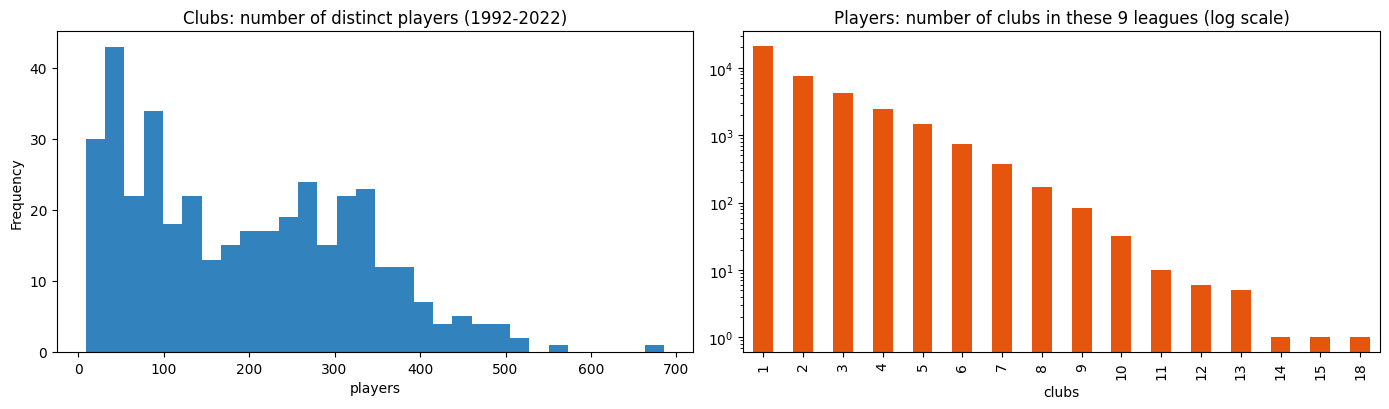

In [25]:
ties = d[["player", "club"]].drop_duplicates()
COUNTRY = d.groupby("club")["country"].agg(lambda s: s.mode()[0])

B = nx.Graph()
B.add_nodes_from(ties["club"].unique(), bipartite="club")
B.add_nodes_from(ties["player"].unique(), bipartite="player")
B.add_edges_from(ties.itertuples(index=False))
clubs = set(ties["club"]); players = set(ties["player"])

print(f"Clubs: {len(clubs)} | Players: {len(players):,} | Player-club ties: {B.number_of_edges():,}")
print(f"Bipartite: {bipartite.is_bipartite(B)} | ties within a group: 0 by construction")
print(f"Density: {bipartite.density(B, clubs):.4f} (share of all possible player-club pairs that occur)")

club_deg = ties.groupby("club").size()
player_deg = ties.groupby("player").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
club_deg.plot.hist(bins=30, ax=axes[0], color="#3182bd")
axes[0].set_title("Clubs: number of distinct players (1992-2022)"); axes[0].set_xlabel("players")
player_deg.value_counts().sort_index().plot.bar(ax=axes[1], color="#e6550d", logy=True)
axes[1].set_title("Players: number of clubs in these 9 leagues (log scale)"); axes[1].set_xlabel("clubs")
plt.tight_layout(); plt.show()

## 4. Project onto the clubs
In the club projection, two clubs are tied if at least one player played for both, and the weight is the number of players they shared over the 30 years.

In [26]:
C = bipartite.weighted_projected_graph(B, clubs)
w = pd.Series([e["weight"] for *_, e in C.edges(data=True)])

print(f"Club projection: {C.number_of_nodes()} clubs, {C.number_of_edges():,} ties, density {nx.density(C):.2f}")
print(f"Shared players per tie: median {w.median():.0f}, 90th percentile {w.quantile(.9):.0f}, max {w.max():.0f}")
print(f"Connected components: {nx.number_connected_components(C)}")

Club projection: 386 clubs, 19,814 ties, density 0.27
Shared players per tie: median 2, 90th percentile 11, max 62
Connected components: 1


The club projection is one connected "hairball": 386 clubs with almost 20,000 ties, and every club is linked to the rest of Europe through at least one player. Most ties are weak (half of them rest on one or two players). To see real structure, the network has to be reduced.

## 5. Reducing the network with the island method
The island method treats edge weights like terrain: imagine the network as a landscape and raise the water level step by step. At each level, only ties at least as strong as the water level stay above water. Weakly connected areas sink, and the strongly connected groups remain as separate islands: connected components between a minimum and a maximum size.

Below is the method, following the book's `trim_edges` and `island_method` functions.

In [27]:
def trim_edges(g, weight=1):
    """Keep only edges with weight >= the water level."""
    g2 = nx.Graph()
    g2.add_edges_from((u, v, e) for u, v, e in g.edges(data=True) if e["weight"] >= weight)
    return g2

def island_method(g, levels):
    """Return [(water level, trimmed graph)] for each water level."""
    return [(t, trim_edges(g, t)) for t in levels]

def islands(g, min_size=3, max_size=None):
    """Connected components of a trimmed graph that count as islands."""
    max_size = max_size or g.number_of_nodes()
    return sorted([c for c in nx.connected_components(g) if min_size <= len(c) <= max_size], key=len, reverse=True)

def draw_islands(g, isl, color_of, label_of, title, ncols=4, panel=3.6, big_first=False, font=7):
    # draw each island in its own panel so separate islands never overlap
    n = len(isl)
    if big_first:
        nrows = max(2, int(np.ceil((n - 1 + 4) / ncols)))
        fig = plt.figure(figsize=(ncols * panel, nrows * panel))
        gs = fig.add_gridspec(nrows, ncols)
        axes = [fig.add_subplot(gs[0:2, 0:2])]
        free = [(r, c) for r in range(nrows) for c in range(ncols) if not (r < 2 and c < 2)]
        axes += [fig.add_subplot(gs[r, c]) for r, c in free[:n - 1]]
    else:
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * panel, nrows * panel))
        axes = list(np.atleast_1d(axes).ravel())
    for i, (ax, nodes) in enumerate(zip(axes, isl)):
        sub = g.subgraph(nodes)
        pos = nx.kamada_kawai_layout(sub, weight=None)
        wts = [e["weight"] for *_, e in sub.edges(data=True)]
        nx.draw_networkx_edges(sub, pos, ax=ax, width=[0.4 + 2.5 * (x - min(wts)) / (max(wts) - min(wts) + 1e-9) for x in wts], alpha=0.35)
        nx.draw_networkx_nodes(sub, pos, ax=ax, node_color=[color_of(v) for v in sub], node_size=110, edgecolors="white")
        nx.draw_networkx_labels(sub, pos, ax=ax, labels={v: label_of(v) for v in sub}, font_size=font)
        ax.set_title(f"Island {i + 1} ({len(nodes)})", fontsize=10)
        ax.margins(0.18); ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

def country_mix(nodes):
    return ", ".join(f"{c} {n}" for c, n in COUNTRY[list(nodes)].value_counts().items())

LEVELS = [1, 3, 5, 8, 10, 12, 15, 18, 20, 22, 25, 30, 35, 40]
rows = []
for t, g in island_method(C, LEVELS):
    isl = islands(g)
    rows.append({"water level (shared players >=)": t, "clubs above water": g.number_of_nodes(),
                 "ties above water": g.number_of_edges(), "islands (3+ clubs)": len(isl),
                 "island sizes": [len(c) for c in isl][:8],
                 "largest islands by country": " | ".join(country_mix(c) for c in isl[:4])})
levels_table = pd.DataFrame(rows)
levels_table

,water level (shared players >=),clubs above water,ties above water,islands (3+ clubs),island sizes,largest islands by country
0,1,386,19814,1,[386],"England 67, Italy 54, Russia 51, Spain 48, France 47, Portugal 44, Germany 44, Netherlands 31"
1,3,375,7485,1,[375],"England 66, Italy 54, Russia 50, Spain 48, France 45, Portugal 43, Germany 38, Netherlands 31"
2,5,349,4718,1,[349],"England 61, Italy 53, Russia 49, Spain 43, Portugal 40, France 39, Germany 33, Netherlands 31"
3,8,306,2987,1,[306],"England 54, Italy 49, Russia 39, Portugal 39, Spain 36, France 32, Netherlands 29, Germany 28"
4,10,280,2291,1,[280],"England 52, Italy 45, Russia 35, Portugal 35, Spain 32, France 29, Netherlands 28, Germany 24"
5,12,245,1756,2,"[213, 32]","England 49, Italy 37, Portugal 32, Spain 26, France 24, Netherlands 24, Germany 21 | Russia 32"
6,15,218,1142,3,"[175, 27, 16]","England 47, Italy 31, Portugal 29, Spain 23, Netherlands 23, France 22 | Russia 27 | Germany 16"
7,18,188,742,3,"[155, 21, 12]","England 45, Italy 29, Portugal 23, Netherlands 21, Spain 19, France 18 | Russia 21 | Germany 12"
8,20,169,562,3,"[142, 20, 5]","England 41, Italy 27, Portugal 22, Netherlands 20, Spain 16, France 16 | Russia 20 | Germany 5"
9,22,144,419,3,"[111, 16, 13]","England 35, Italy 25, Portugal 21, Netherlands 16, Spain 14 | Russia 16 | France 13"


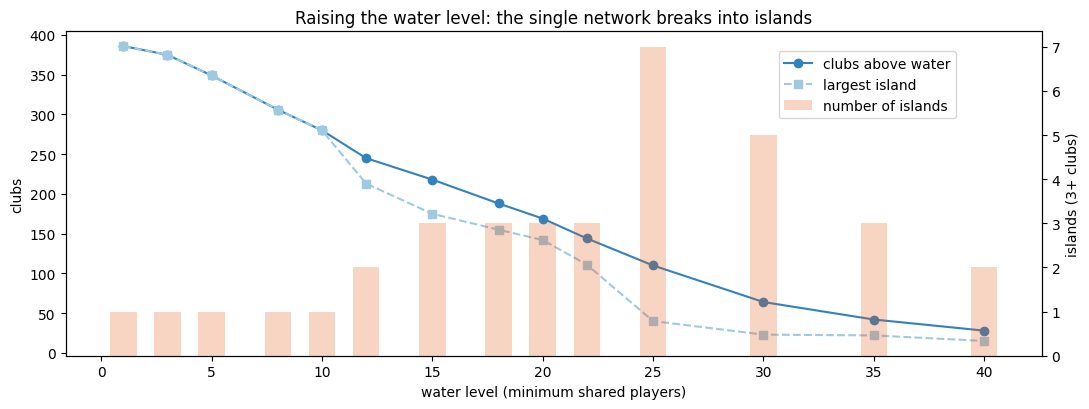

In [28]:
fig, ax1 = plt.subplots(figsize=(11, 4.2))
ax1.plot(levels_table.iloc[:, 0], levels_table["clubs above water"], "o-", color="#3182bd", label="clubs above water")
ax1.plot(levels_table.iloc[:, 0], [s[0] if s else 0 for s in levels_table["island sizes"]], "s--",
         color="#9ecae1", label="largest island")
ax1.set_xlabel("water level (minimum shared players)"); ax1.set_ylabel("clubs")
ax2 = ax1.twinx()
ax2.bar(levels_table.iloc[:, 0], levels_table["islands (3+ clubs)"], alpha=0.25, color="#e6550d", width=1.2,
        label="number of islands")
ax2.set_ylabel("islands (3+ clubs)")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.title("Raising the water level: the single network breaks into islands")
plt.tight_layout(); plt.show()

### 5a. The order in which the islands appear
Following one island as the water rises shows which leagues are the most internally connected. Russia separates first, then Germany, and by level 25 Europe has broken into national islands.

In [29]:
first_split = {}
for t, g in island_method(C, range(1, 46)):
    for c in islands(g):
        mix = COUNTRY[list(c)].value_counts()
        if mix.iloc[0] / len(c) >= 0.9:          # an island that is (almost) all one country
            first_split.setdefault(mix.index[0], (t, len(c)))
pd.DataFrame(first_split, index=["first water level as its own island", "clubs in it"]).T \
  .sort_values("first water level as its own island")

,first water level as its own island,clubs in it
Russia,11,33
Germany,13,20
France,21,16
England,23,27
Portugal,23,19
Spain,23,8
Italy,26,25
Netherlands,26,14


### 5b. The islands at water level 25
I pick water level 25 (clubs that shared at least 25 players) for a closer look, because it is the level where the national groups have separated but most leagues still have an island. Each island is a group of clubs that exchanged players very heavily over 30 years.

In [30]:
WATER = 25
C25 = trim_edges(C, WATER)
isl25 = islands(C25)
island_of = {club: i + 1 for i, c in enumerate(isl25) for club in c}

summary = []
for i, c in enumerate(isl25, 1):
    sub = C25.subgraph(c)
    strength = dict(sub.degree(weight="weight"))
    summary.append({"island": i, "clubs": len(c), "countries": country_mix(c),
                    "most connected clubs": ", ".join(sorted(strength, key=strength.get, reverse=True)[:5]),
                    "strongest tie": max(((u, v, e["weight"]) for u, v, e in sub.edges(data=True)), key=lambda x: x[2])})
pd.DataFrame(summary).set_index("island")

,clubs,countries,most connected clubs,strongest tie
island,,,,
1,40,"Italy 23, Netherlands 14, England 2, Spain 1","Parma, UC Sampdoria, ACF Fiorentina, Bologna FC 1909, Torino FC","(Inter Milan, Parma, 62)"
2,18,Portugal 18,"SC Braga, Vitória Setúbal FC, FC Porto, SL Benfica, CF Os Belenenses","(SC Braga, FC Porto, 55)"
3,11,England 11,"Leeds United, Derby County, Leicester City, Middlesbrough FC, Queens Park Rangers","(Derby County, Leicester City, 32)"
4,10,France 10,"Olympique Marseille, AS Monaco, Stade Rennais FC, Olympique Lyon, Paris Saint-Germain","(Olympique Marseille, AS Monaco, 36)"
5,9,Russia 9,"FK Rostov, Krylya Sovetov Samara, Dynamo Moscow, Spartak Moscow, Lokomotiv Moscow","(FK Rostov, Rubin Kazan, 37)"
6,5,Spain 5,"Atlético de Madrid, RCD Mallorca, RCD Espanyol Barcelona, Sevilla FC, Getafe CF","(Atlético de Madrid, RCD Mallorca, 31)"
7,3,Russia 3,"CSKA Moscow, FC Moscow, Torpedo Moscow","(FC Moscow, CSKA Moscow, 25)"


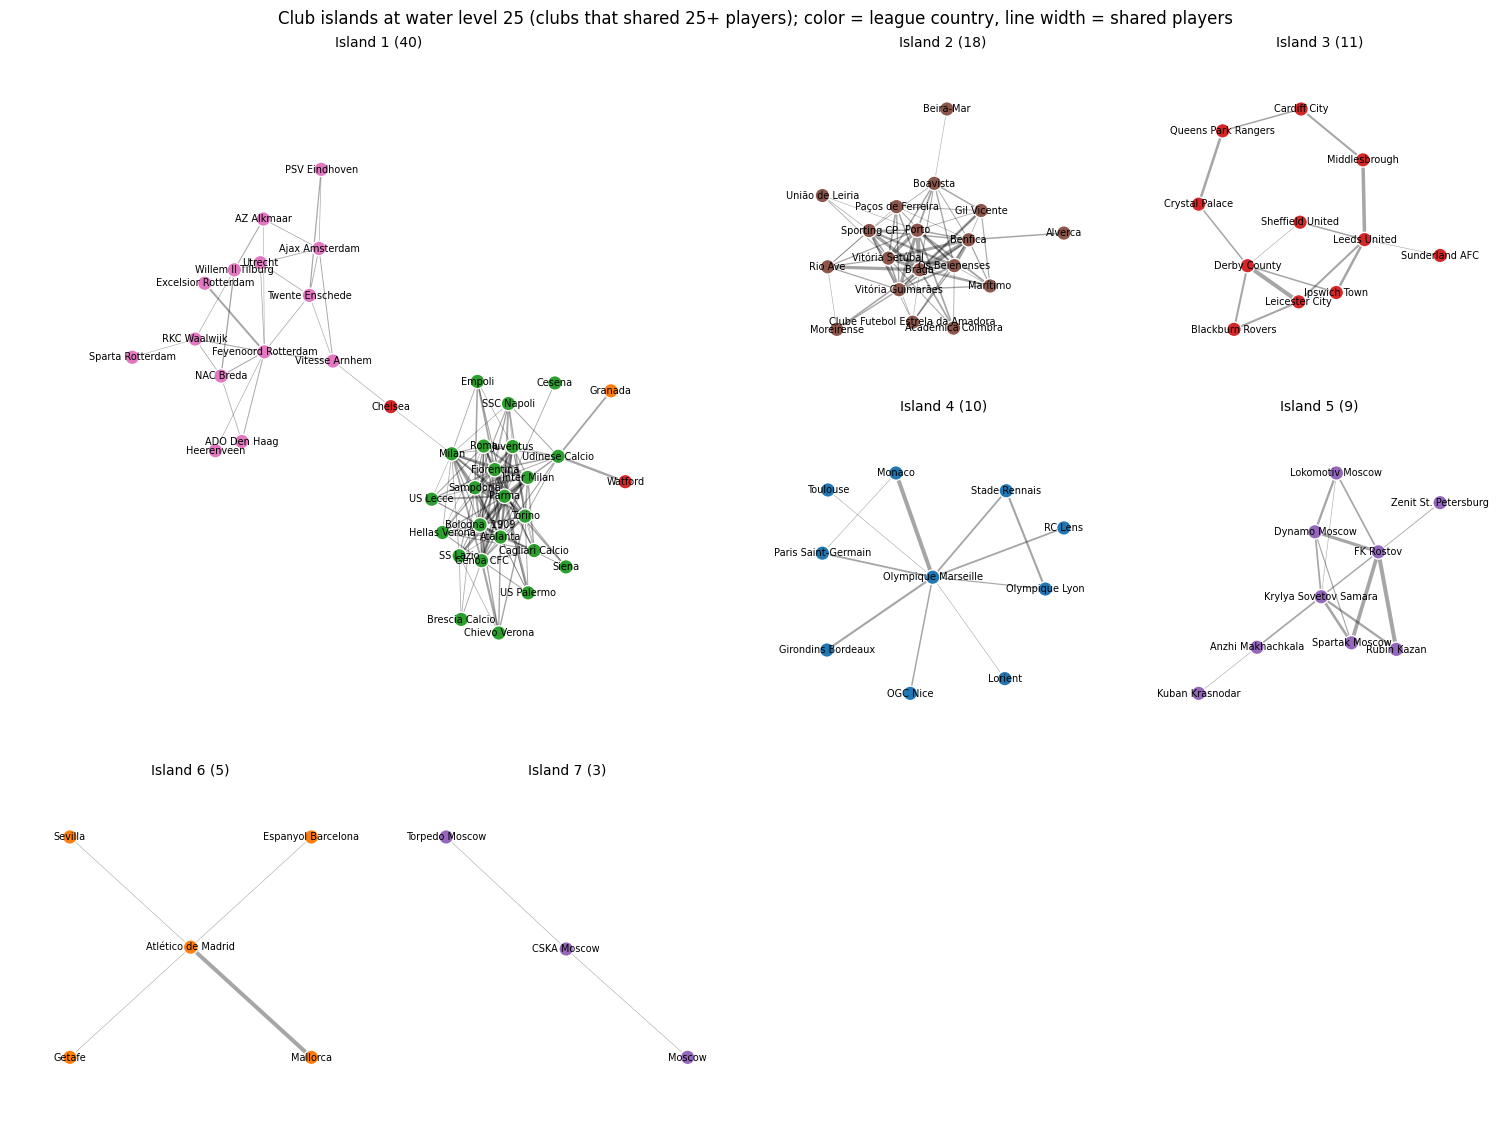

In [31]:
PALETTE = {"England": "#d62728", "Italy": "#2ca02c", "Spain": "#ff7f0e", "Germany": "#7f7f7f", "France": "#1f77b4",
           "Portugal": "#8c564b", "Netherlands": "#e377c2", "Russia": "#9467bd"}
short_club = lambda c: re.sub(r"\s*\(.*?\)|\b(FC|AC|SC|CF|AS|UC|SL|CS|RCD|ACF|BC)\b", "", c).strip()

draw_islands(C25, isl25, color_of=lambda c: PALETTE[COUNTRY[c]], label_of=short_club, big_first=True, ncols=4, panel=3.8,
             title=f"Club islands at water level {WATER} (clubs that shared {WATER}+ players); color = league country, line width = shared players")

### 5c. The ties that cross borders
The islands are mostly national, so the few strong ties between leagues are the most revealing. These are the strongest ties between clubs in different countries.

In [32]:
cross = sorted(((e["weight"], u, v) for u, v, e in C.edges(data=True) if COUNTRY[u] != COUNTRY[v]), reverse=True)
cross_df = pd.DataFrame([{"club 1": u, "country 1": COUNTRY[u], "club 2": v, "country 2": COUNTRY[v],
                          "shared players": wt} for wt, u, v in cross[:15]])
cross_df

,club 1,country 1,club 2,country 2,shared players
0,Watford FC,England,Udinese Calcio,Italy,44
1,Granada CF,Spain,Udinese Calcio,Italy,39
2,Chelsea FC,England,Vitesse Arnhem,Netherlands,26
3,Chelsea FC,England,AC Milan,Italy,25
4,SL Benfica,Portugal,Valencia CF,Spain,22
5,FC Barcelona,Spain,Ajax Amsterdam,Netherlands,22
6,AC Milan,Italy,FC Barcelona,Spain,22
7,Watford FC,England,Granada CF,Spain,21
8,Atlético de Madrid,Spain,SL Benfica,Portugal,21
9,AC Milan,Italy,AS Monaco,France,20


### 5d. Which clubs connect the islands?
At water level 15 most of Western Europe is still one large component. Betweenness centrality there (with distance = 1 / shared players, so heavy exchange means short distance) shows the clubs that hold the different leagues together. I also report each club's share of shared players that came from clubs in other countries.

In [33]:
C15 = trim_edges(C, 15)
for u, v, e in C15.edges(data=True):
    e["distance"] = 1 / e["weight"]
btw = nx.betweenness_centrality(C15, weight="distance")

strength = dict(C.degree(weight="weight"))
foreign = {c: sum(e["weight"] for n, e in C[c].items() if COUNTRY[n] != COUNTRY[c]) for c in C}
club_table = pd.DataFrame({"country": COUNTRY, "distinct players": club_deg,
                           "shared players (weighted degree)": pd.Series(strength),
                           "share with foreign clubs": pd.Series(foreign) / pd.Series(strength),
                           "betweenness (level 15)": pd.Series(btw)}).fillna({"betweenness (level 15)": 0})

print("Clubs with the most distinct players:")
display(club_table.sort_values("distinct players", ascending=False).head(8))
print("Main bridges between leagues (betweenness at water level 15):")
display(club_table.sort_values("betweenness (level 15)", ascending=False).head(10))

Clubs with the most distinct players:


,country,distinct players,shared players (weighted degree),share with foreign clubs,betweenness (level 15)
Parma,Italy,686,1397,0.201145,0.042413
Inter Milan,Italy,554,1447,0.407740,0.093702
Atalanta BC,Italy,525,1100,0.175455,0.021377
Udinese Calcio,Italy,514,1102,0.395644,0.099846
UC Sampdoria,Italy,504,1220,0.222951,0.005248
SL Benfica,Portugal,495,1350,0.496296,0.150068
ACF Fiorentina,Italy,491,1287,0.307692,0.001579
AS Roma,Italy,483,1219,0.374077,0.001835


Main bridges between leagues (betweenness at water level 15):


,country,distinct players,shared players (weighted degree),share with foreign clubs,betweenness (level 15)
FC Barcelona,Spain,255,756,0.628307,0.152159
Chelsea FC,England,324,1002,0.547904,0.151988
SL Benfica,Portugal,495,1350,0.496296,0.150068
AC Milan,Italy,460,1309,0.418640,0.136841
AS Monaco,France,400,1045,0.599043,0.108935
Atlético de Madrid,Spain,315,863,0.480881,0.108594
Watford FC,England,350,941,0.363443,0.105607
Valencia CF,Spain,305,827,0.498186,0.104476
Udinese Calcio,Italy,514,1102,0.395644,0.099846
Ajax Amsterdam,Netherlands,330,875,0.553143,0.096219


In [34]:
by_country = club_table.groupby("country").agg(clubs=("distinct players", "size"),
                                               players_per_club=("distinct players", "mean"),
                                               foreign_share=("share with foreign clubs", "mean"))
own = {}
for ctry in by_country.index:
    cs = [c for c in C if COUNTRY[c] == ctry]
    sub = C.subgraph(cs)
    own[ctry] = np.mean([e["weight"] for *_, e in sub.edges(data=True)])
by_country["avg shared players between two domestic clubs"] = pd.Series(own)
by_country.sort_values("avg shared players between two domestic clubs", ascending=False).round(2)

,clubs,players_per_club,foreign_share,avg shared players between two domestic clubs
country,,,,
Netherlands,31,237.52,0.27,10.07
Portugal,44,209.91,0.22,9.43
Italy,54,233.44,0.20,9.37
England,67,243.13,0.19,8.52
France,47,177.30,0.34,6.11
Russia,51,138.63,0.11,5.99
Spain,48,161.77,0.39,5.65
Germany,44,157.89,0.35,5.36


## 6. The players
Now the other group. How many clubs does a player play for, does it depend on his position, how often do careers cross borders, and how has movement changed over time?

In [35]:
first_pos = d.dropna(subset=["pos_group"]).groupby("player")["pos_group"].agg(lambda s: s.mode()[0])
first_year = d.groupby("player")["year"].min()
countries_per_player = ties.assign(country=ties["club"].map(COUNTRY)).groupby("player")["country"].nunique()

pl = pd.DataFrame({"clubs": player_deg, "position": first_pos, "countries": countries_per_player,
                   "first_year": first_year, "ambiguous": d.drop_duplicates("player").set_index("player")["ambiguous"]})

print(f"Players at only one club in these leagues: {(pl.clubs == 1).mean():.0%}")
print(f"Players at 5+ clubs: {(pl.clubs >= 5).mean():.1%} | mean clubs per player: {pl.clubs.mean():.2f}")
print(f"Players who played in more than one of these countries: {(pl.countries > 1).mean():.0%} of all players, "
      f"{(pl.loc[pl.clubs > 1, 'countries'] > 1).mean():.0%} of players with 2+ clubs")

pos_tab = pl.groupby("position")["clubs"].agg(["mean", "median", "count"])
pos_tab["share with 5+ clubs"] = pl.groupby("position")["clubs"].apply(lambda s: (s >= 5).mean())
H, p = stats.kruskal(*[g["clubs"].values for _, g in pl.dropna(subset=["position"]).groupby("position")])
print(f"\nClubs per player by position (Kruskal-Wallis H = {H:.1f}, p = {p:.1e}):")
display(pos_tab.loc[["Goalkeeper", "Defender", "Midfielder", "Forward"]].round(3))

Players at only one club in these leagues: 55%
Players at 5+ clubs: 7.5% | mean clubs per player: 1.98
Players who played in more than one of these countries: 15% of all players, 33% of players with 2+ clubs

Clubs per player by position (Kruskal-Wallis H = 50.6, p = 6.1e-11):


,mean,median,count,share with 5+ clubs
position,,,,
Goalkeeper,1.894,1.0,3784,0.068
Defender,1.967,1.0,12003,0.071
Midfielder,1.936,1.0,11855,0.068
Forward,2.085,1.0,10493,0.091


In [36]:
print("The biggest journeymen (names that identify one person only):")
jm = pl[~pl.ambiguous].sort_values("clubs", ascending=False).head(10)
jm = jm.assign(clubs_list=[", ".join(sorted(ties.loc[ties.player == p, "club"])) for p in jm.index])
jm.index = jm.index.str.replace(r" #\d+$", "", regex=True)
jm[["clubs", "countries", "position", "clubs_list"]]

The biggest journeymen (names that identify one person only):


,clubs,countries,position,clubs_list
player,,,,
Marco Borriello,13,2,Forward,"AC Milan, AS Roma, Atalanta BC, Cagliari Calcio, Carpi FC 1909, Empoli FC, Genoa CFC, Juventus FC, Reggina Calcio, S..."
Nicola Amoruso,13,1,Forward,"AC Perugia, AC Siena, Atalanta BC, Calcio Padova, Como Calcio, FC Messina Peloro, Juventus FC, Modena FC, Parma, Reg..."
Loïc Rémy,12,3,Forward,"Chelsea FC, Crystal Palace, Getafe CF, LOSC Lille, Newcastle United, OGC Nice, Olympique Lyon, Olympique Marseille, ..."
Greg Halford,12,1,Defender,"Birmingham City, Brighton & Hove Albion, Cardiff City, Charlton Athletic, Colchester United, Nottingham Forest, Port..."
Marcus Bent,12,1,Forward,"Birmingham City, Blackburn Rovers, Charlton Athletic, Crystal Palace, Everton FC, Ipswich Town, Leicester City, Midd..."
Alou Diarra,12,3,Midfielder,"AC Le Havre, AS Nancy-Lorraine, Bayern Munich, Charlton Athletic, FC Girondins Bordeaux, Liverpool FC, Olympique Lyo..."
Kevin-Prince Boateng,12,4,Midfielder,"AC Milan, ACF Fiorentina, Borussia Dortmund, Eintracht Frankfurt, FC Barcelona, FC Schalke 04, Genoa CFC, Hertha BSC..."
Scott Sinclair,12,1,Forward,"Aston Villa, Birmingham City, Charlton Athletic, Chelsea FC, Crystal Palace, Manchester City, Plymouth Argyle, Prest..."
Chris Wood,11,1,Forward,"Barnsley FC, Birmingham City, Bristol City, Burnley FC, Ipswich Town, Leeds United, Leicester City, Millwall FC, New..."


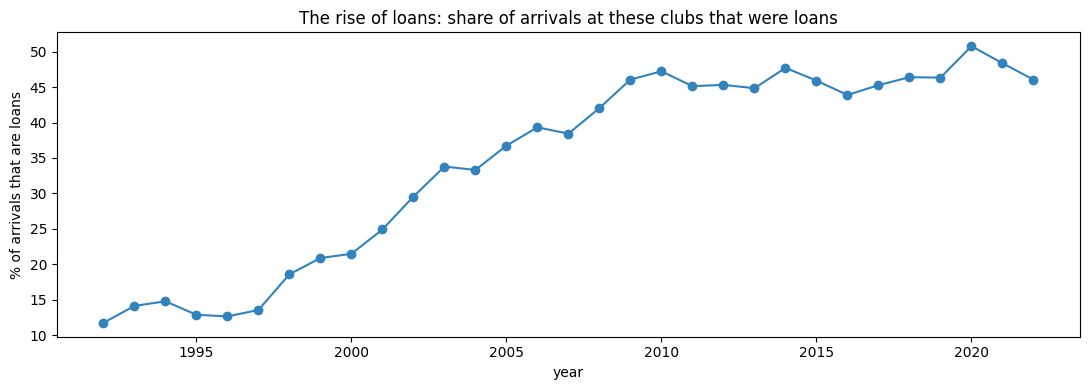

Loan share of arrivals: 12% in 1992 -> 46% on average in 2010-2022


In [37]:
moves = d[d["transfer_movement"] == "in"]
trend = moves.groupby("year").agg(loan_share=("loan", "mean"), arrivals=("player", "size"))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(trend.index, trend["loan_share"] * 100, "o-", color="#3182bd")
ax.set_ylabel("% of arrivals that are loans"); ax.set_xlabel("year")
ax.set_title("The rise of loans: share of arrivals at these clubs that were loans")
plt.tight_layout(); plt.show()
print(f"Loan share of arrivals: {trend.loan_share.iloc[0]:.0%} in {trend.index[0]} -> "
      f"{trend.loc[2010:2022, 'loan_share'].mean():.0%} on average in 2010-2022")

### 6a. Reducing the players' network with the island method
Projecting onto the 38,000 players gives millions of ties (two players are tied if they ever played for the same club, even 20 years apart), far too many to analyze. So I apply the island method to the players too. To keep it manageable, I use players with 3 or more clubs and unambiguous names. Two players are tied by the number of clubs they have in common, and islands appear as the water rises. A strong tie here means two careers that followed the same path through several clubs.

In [38]:
core = pl[(pl.clubs >= 3) & (~pl.ambiguous)].index
pt = ties[ties.player.isin(core)]
p_idx = {p: i for i, p in enumerate(pt.player.unique())}; c_idx = {c: i for i, c in enumerate(pt.club.unique())}
plist = list(p_idx)
M = sparse.csr_matrix((np.ones(len(pt)), (pt.player.map(p_idx), pt.club.map(c_idx))))
shared = sparse.triu(M @ M.T, k=1).tocoo()

print(f"Players: {len(plist):,} | player pairs that shared at least one club: {shared.nnz:,}")
print("Pairs by number of shared clubs:", pd.Series(shared.data).value_counts().sort_index().astype(int).to_dict())

P = nx.Graph()
P.add_edges_from((plist[i], plist[j], {"weight": int(wt)}) for i, j, wt in zip(shared.row, shared.col, shared.data) if wt >= 3)

prow = []
for t, g in island_method(P, [3, 4, 5, 6]):
    isl = islands(g)
    prow.append({"water level (shared clubs >=)": t, "players above water": g.number_of_nodes(),
                 "islands (3+ players)": len(isl), "island sizes": [len(c) for c in isl][:8]})
pd.DataFrame(prow)

Players: 8,597 | player pairs that shared at least one club: 2,389,653
Pairs by number of shared clubs: {1.0: 2152348, 2.0: 217888, 3.0: 17970, 4.0: 1349, 5.0: 95, 6.0: 3}


,water level (shared clubs >=),players above water,islands (3+ players),island sizes
0,3,5205,28,"[4885, 6, 6, 5, 5, 5, 4, 4]"
1,4,1078,32,"[646, 54, 51, 14, 12, 7, 6, 6]"
2,5,131,12,"[20, 13, 11, 7, 5, 4, 4, 3]"
3,6,6,0,[]


At water level 5 (players who shared at least five clubs), the players' network breaks into small islands. Each island is a group of players whose careers ran through the same set of clubs.

In [39]:
P5 = trim_edges(P, 5)
rows = []
for i, c in enumerate(islands(P5), 1):
    club_counts = pt[pt.player.isin(c)].club.value_counts()
    rows.append({"island": i, "players": len(c),
                 "countries of their 6 most common clubs": country_mix(club_counts.index[:6]),
                 "most common clubs": ", ".join(club_counts.index[:5]),
                 "example players": ", ".join(sorted(re.sub(r" #\d+$", "", p) for p in c)[:6])})
player_islands = pd.DataFrame(rows).set_index("island")
player_islands.head(10)

,players,countries of their 6 most common clubs,most common clubs,example players
island,,,,
1,20,England 6,"Birmingham City, Ipswich Town, Queens Park Rangers, Blackburn Rovers, Derby County","Andros Townsend, Bradley Orr, Carl Ikeme, Chris Wood, Conor Gallagher, DJ Campbell"
2,13,Italy 6,"Hellas Verona, AC Milan, UC Sampdoria, Brescia Calcio, ACF Fiorentina","Aimo Diana, Alessio Cerci, Christian Vieri, Domenico Morfeo, Emiliano Bonazzoli, Eugenio Corini"
3,11,Italy 6,"SSC Napoli, Juventus FC, Torino FC, UC Sampdoria, US Lecce","Cesare Bovo, Fabio Pecchia, Fabio Quagliarella, Ferdinando Coppola, Guglielmo Stendardo, Manuele Blasi"
4,7,Italy 6,"Genoa CFC, US Palermo, ACF Fiorentina, Parma, Hellas Verona","Alberto Gilardino, Aleandro Rosi, Cristiano Lupatelli, Dario Dainelli, Francesco Modesto, Luca Toni"
5,5,England 6,"Cardiff City, Norwich City, West Bromwich Albion, Queens Park Rangers, Nottingham Forest","Gary O'Neil, Greg Halford, Jordan Hugill, Lee Camp, Robert Earnshaw"
6,4,"France 3, England 3","Stade Rennais FC, RC Lens, SC Bastia, Liverpool FC, Portsmouth FC","Alou Diarra, Djimi Traoré, Grégory Vignal, Tony Vairelles"
7,4,Italy 6,"UC Sampdoria, AC Milan, SPAL, Atalanta BC, Genoa CFC","Alberto Paloschi, Ervin Zukanovic, Marco Borriello, Pasquale Foggia"
8,3,England 6,"Swansea City, Derby County, Huddersfield Town, Bristol City, Nottingham Forest","Andy King, Ben Hamer, Jamie Paterson"
9,3,"France 5, England 1","Olympique Marseille, OGC Nice, Newcastle United, FC Girondins Bordeaux, Olympique Lyon","Hatem Ben Arfa, Kaba Diawara, Loïc Rémy"


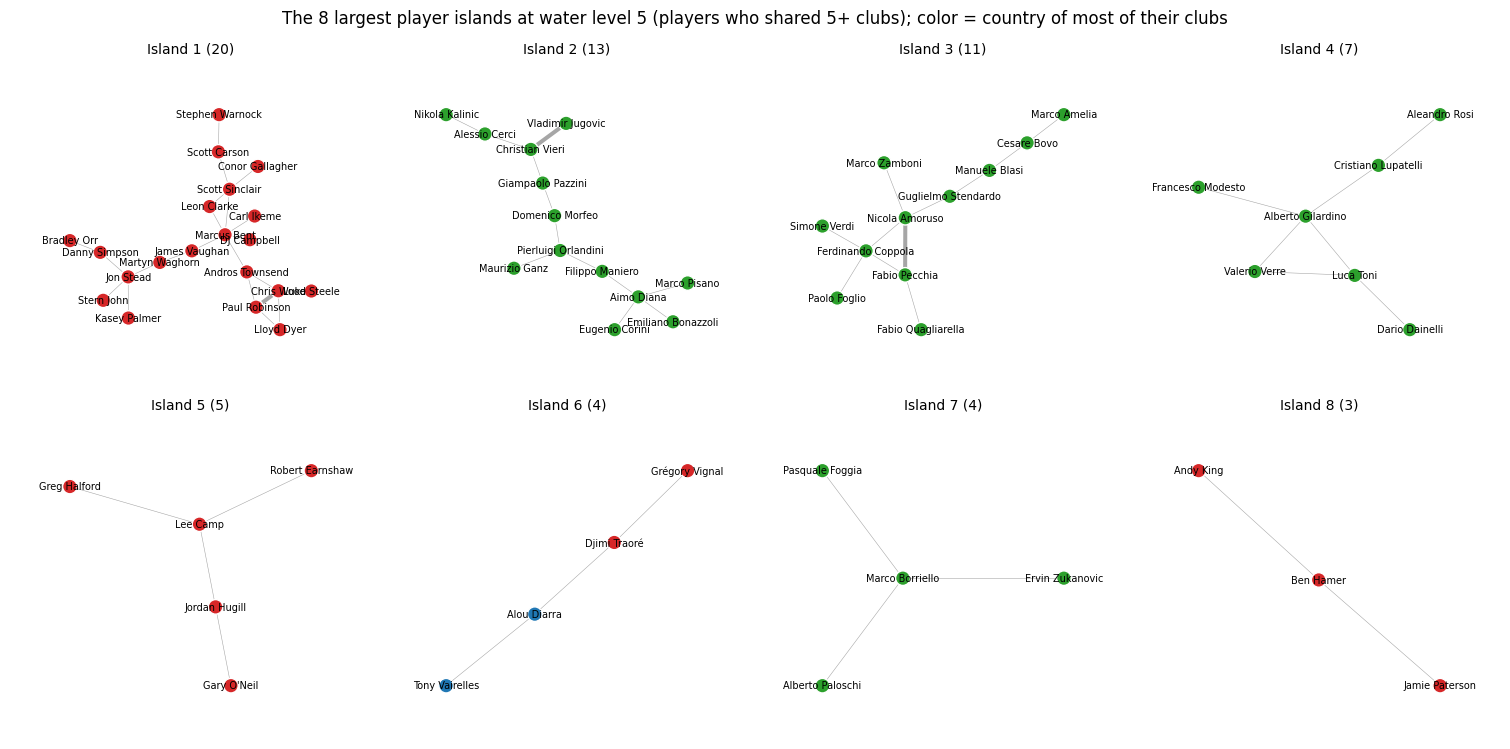

In [40]:
dominant = {p: COUNTRY[pt[pt.player == p].club].value_counts().index[0] for p in P5}
isl5 = islands(P5)
draw_islands(P5, isl5[:8], color_of=lambda p: PALETTE[dominant[p]], label_of=lambda p: re.sub(r" #\d+$", "", p),
             ncols=4, panel=3.8, font=7,
             title="The 8 largest player islands at water level 5 (players who shared 5+ clubs); color = country of most of their clubs")

## 7. Robustness check: removing ambiguous names
Players with ambiguous names (8.5%, mostly single names and common Portuguese and Brazilian names such as "Adriano" or "João Pedro") might still merge several people, and that would create false ties between clubs. Here I rebuild the club projection without them and run the island method again.

In [41]:
ties_clean = ties[~ties.player.str.replace(r" #\d+$", "", regex=True).isin(AMBIGUOUS)]
Bc = nx.Graph(); Bc.add_edges_from(ties_clean.itertuples(index=False))
Cc = bipartite.weighted_projected_graph(Bc, set(ties_clean.club))

comp = []
for t in [12, 15, 20, 25, 30]:
    for label, g in [("all players", C), ("without ambiguous names", Cc)]:
        isl = islands(trim_edges(g, t))
        comp.append({"water level": t, "version": label, "islands": len(isl),
                     "largest islands by country": " | ".join(country_mix(c) for c in isl[:5])})
display(pd.DataFrame(comp).set_index(["water level", "version"]))

cross_c = sorted(((e["weight"], u, v) for u, v, e in Cc.edges(data=True) if COUNTRY[u] != COUNTRY[v]), reverse=True)[:5]
print("Strongest cross-border ties without ambiguous names:", [(u, v, int(wt)) for wt, u, v in cross_c])

islands  \
water level version                            
12          all players                    2   
            without ambiguous names        3   
15          all players                    3   
            without ambiguous names        3   
20          all players                    3   
            without ambiguous names        5   
25          all players                    7   
            without ambiguous names        6   
30          all players                    5   
            without ambiguous names        5   

                                                                                                           largest islands by country  
water level version                                                                                                                    
12          all players                England 49, Italy 37, Portugal 32, Spain 26, France 24, Netherlands 24, Germany 21 | Russia 32  
            without ambiguous names   England 49, Italy 37, France 24, Spain 24, Netherlands 24, Portugal 21 | Russia 31 | Germany 21  
15          all players               England 47, Italy 31, Portugal 29, Spain 23, Netherlands 23, France 22 | Russia 27 | Germany 16  
            without ambiguous names   England 47, Italy 30, Netherlands 23, France 22, Portugal 19, Spain 18 | Russia 24 | Germany 16  
20          all players                England 41, Italy 27, Portugal 22, Netherlands 20, Spain 16, France 16 | Russia 20 | Germany 5  
            without ambiguous names  England 40, Italy 26, Netherlands 20, Spain 10 | Russia 18 | France 16 | Portugal 11 | Germany 4  
25          all players                Italy 23, Netherlands 14, England 2, Spain 1 | Portugal 18 | England 11 | France 10 | Russia 9  
            without ambiguous names                  Italy 23, Spain 1, England 1 | Netherlands 14 | England 10 | France 9 | Russia 8  
30          all players                              Italy 21, Spain 1, England 1 | Portugal 16 | Russia 6 | Netherlands 6 | France 3  
            without ambiguous names                Italy 21, Spain 1, England 1 | Russia 5 | Netherlands 3 | Netherlands 3 | France 3

Strongest cross-border ties without ambiguous names: [('Watford FC', 'Udinese Calcio', 41), ('Granada CF', 'Udinese Calcio', 34), ('Chelsea FC', 'Vitesse Arnhem', 24), ('Chelsea FC', 'AC Milan', 23), ('AC Milan', 'FC Barcelona', 20)]


## 8. Summary of results

In [42]:
print("=" * 90)
print(f"Two-mode network: {len(clubs)} clubs x {len(players):,} players, {B.number_of_edges():,} ties (1992-2022, 9 leagues)")
print(f"Club projection: {C.number_of_edges():,} ties, density {nx.density(C):.2f}, one component")
print(f"Islands at water level {WATER}: {len(isl25)} | " + " | ".join(country_mix(c) for c in isl25))
print("Strongest cross-border ties: " + ", ".join(f"{u}-{v} ({int(wt)})" for wt, u, v in cross[:4]))
top_b = club_table.sort_values("betweenness (level 15)", ascending=False).head(3)
print("Top bridges (betweenness, level 15): " + ", ".join(f"{c} ({b:.2f})" for c, b in top_b["betweenness (level 15)"].items()))
print(f"Players: {(pl.clubs == 1).mean():.0%} at one club; {(pl.loc[pl.clubs > 1, 'countries'] > 1).mean():.0%} of multi-club players crossed a border")
print(f"Loan share of arrivals: {trend.loan_share.iloc[0]:.0%} (1992) -> {trend.loc[2010:2022, 'loan_share'].mean():.0%} (2010-2022 average)")
print("=" * 90)

Two-mode network: 386 clubs x 38,135 players, 75,610 ties (1992-2022, 9 leagues)
Club projection: 19,814 ties, density 0.27, one component
Islands at water level 25: 7 | Italy 23, Netherlands 14, England 2, Spain 1 | Portugal 18 | England 11 | France 10 | Russia 9 | Spain 5 | Russia 3
Strongest cross-border ties: Watford FC-Udinese Calcio (44), Granada CF-Udinese Calcio (39), Chelsea FC-Vitesse Arnhem (26), Chelsea FC-AC Milan (25)
Top bridges (betweenness, level 15): FC Barcelona (0.15), Chelsea FC (0.15), SL Benfica (0.15)
Players: 55% at one club; 33% of multi-club players crossed a border
Loan share of arrivals: 12% (1992) -> 46% (2010-2022 average)


## 9. Conclusions

### The clubs
Without reduction, the club network says almost nothing. All 386 clubs form one connected component with 19,814 ties (density 0.27), and half of those ties rest on just one or two shared players. Over 30 years, nearly every club is linked to the rest of Europe through at least one player. The island method reveals national islands.

| Water level | What separates |
|---|---|
| 11 | **Russia** (33 clubs) splits off first |
| 13 | **Germany** (20 clubs) |
| 21 | **France** |
| 23 | **England**, **Portugal** and **Spain** |
| 26 | **Italy** and the **Netherlands** |

At water level 25, there are 7 islands, and each is (almost) a single country.

The order shows two different traits of a league: how closed it is, and how much its clubs trade with each other.
- Russia is the most closed league. Only 11% of its clubs' shared players link them to foreign clubs, so it separates from Western Europe first.
- Germany is the least "liquid" league. Its clubs share the fewest players with each other (5.4 per pair of domestic clubs, the lowest of the 8 countries), so the German island separates early and also sinks early: it has disappeared by level 25.
- Italy, the Netherlands and Portugal trade the most internally (9.4 to 10.1 shared players per pair of domestic clubs), so their islands survive at the highest water levels. Italy is the extreme case. Its island is still the largest at level 40 (15 clubs, alongside a Portuguese island of 9), its strongest tie is Inter-Parma (62 shared players), and the 5 clubs with the most distinct players are all Italian (Parma 686, Inter 554, Atalanta 525, Udinese 514, Sampdoria 504). This likely reflects Italy's heavy use of loans and co-ownership deals during this period.

Inside each island, the structure tells a local story.
- **England**: the island is not the "Big Six" but clubs that moved between the Premier League and the Championship (Leeds, Derby, Leicester, Middlesbrough, Crystal Palace).
- **Portugal:** the island is built around Braga and the Big Three (Braga-Porto, 55 shared players).
- **France:** the island is a hub around Marseille (Marseille-Monaco, 36).
- **Spain:** the island centers on Atlético de Madrid (Atlético-Mallorca, 31).

**The strongest ties that cross borders come from ownership and loan relationships, not geography.**
- **Ownership.** Udinese-Watford (44) and Udinese-Granada (39) are the two strongest cross-border ties in the network, and Watford-Granada (21) completes the triangle. All three clubs were owned by the Pozzo family during this period. Their tie is strong enough to pull Watford and Granada into the Italian island.
- **Loans.** Chelsea-Vitesse (26) reflects Chelsea's well-known loan pipeline to Arnhem. At water level 25, Chelsea is the only bridge between the Dutch and Italian islands.
- **Elite clubs connect the leagues.** At water level 15, the main bridges between leagues (by betweenness) are big international clubs: **Barcelona** (0.15, with 63% of its shared players tied to foreign clubs), **Chelsea** (0.15), **Benfica** (0.15), **AC Milan** (0.14), **Monaco** (0.11) and **Atlético** (0.11).

### The players
- **Most players appear at only one club.** 55% of the 38,135 players appear at a single club in these leagues, the average is about 2 clubs, and only 7.5% played for 5 or more.
- **Forwards move the most.** 9.1% of forwards played for 5+ clubs, compared with 6.8% of goalkeepers and midfielders. The difference is significant (Kruskal–Wallis p = 6e-11) but small.
- **Careers are mostly national.** Only a third (33%) of players with 2+ clubs ever played in a second of these countries. The biggest journeymen, Nicola Amoruso and Marco Borriello (13 clubs each), stayed almost entirely in Italy. Kevin-Prince Boateng and Stéphane Dalmat stand out for playing in 4 countries.
- **Loans have transformed player movement.** Loans were 12% of arrivals in 1992 and 46% on average in 2010-2022.
- **The island method on the players gives national career paths too.** At water level 5 (players who shared at least 5 clubs), 131 players form 12 islands:
    - The largest is a group of English Championship (Ipswich, Birmingham, QPR, Blackburn, Leicester).
    - Several are Serie A groups, such as Vieri and Cerci; Quagliarella and Amoruso; and Toni and Gilardino.
    - The only career path that repeatedly crosses a border is France → England (Alou Diarra, Djimi Traoré, Grégory Vignal; Loïc Rémy and Hatem Ben Arfa).

### Robustness
Removing players with ambiguous names (8.5%) leaves the same national islands and the same top cross-border ties (Watford–Udinese 41, Granada–Udinese 34, Chelsea–Vitesse 24). The exception is Portugal: it separates earlier as a smaller island (11 clubs at level 20) and is gone by level 25. Many common Portuguese and Brazilian names were merged into one "player", so Portugal's internal exchange is somewhat overstated in the main analysis.

### Limitations
- The network only covers the 9 leagues. A player's time at clubs elsewhere (for example in Belgium, Turkey or South America) is invisible, which understates international careers even though I covered the most important leagues.
- Ties are counted over 30 years, so a shared player from 1994 counts as much as one from 2022.
